# 00 - EDA & Preprocessing: Hotel Booking Demand

**Source:** Kaggle - https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand  
**Target:** `is_canceled` (0 = not canceled, 1 = canceled) - binary classification.

    "**Why this dataset:** It is a real problem (hotels want to know which bookings may get canceled). It has 119k rows and 31 features with both numeric and categorical columns. It also has missing values, duplicates and imbalanced classes, so I can do all the preprocessing steps from the assignment."

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ROOT = os.path.abspath('..')
ART = os.path.join(ROOT, 'artifacts')
os.makedirs(ART, exist_ok=True)

df = pd.read_csv(os.path.join(ROOT, 'hotel_bookings.csv'))
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Feature types

In [ ]:
num_all = df.select_dtypes(include='number').columns.drop('is_canceled').tolist()
cat_all = df.select_dtypes(exclude='number').columns.tolist()
print(f'Numeric ({len(num_all)}):', num_all)
print(f'Categorical ({len(cat_all)}):', cat_all)

Numeric (19): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical (12): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


## 2. Class distribution

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


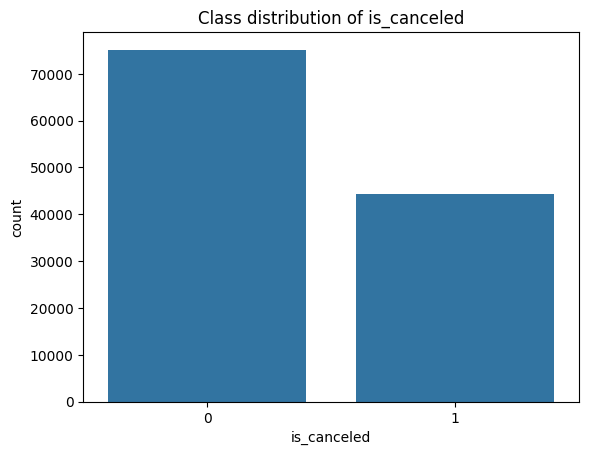

In [ ]:
print(df['is_canceled'].value_counts())
print((df['is_canceled'].value_counts(normalize=True) * 100).round(2))
sns.countplot(x='is_canceled', data=df)
plt.title('Class distribution of is_canceled')
plt.show()

## 3. Missing values

In [ ]:
miss = df.isna().sum()
miss = miss[miss > 0].to_frame('missing')
miss['pct'] = (miss['missing'] / len(df) * 100).round(2)
miss

,missing,pct
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


**How I handle them**
- `company` (~94% missing) and `agent` (~14% missing) are just ID numbers. Missing here means the booking had no company or agent, so I change them to yes/no columns `has_company` and `has_agent` and drop the IDs.
- `children` (4 rows) and `country` (488 rows) are filled later in the pipeline (median and most common value). This is fitted on train data only.

In [ ]:
df['has_agent'] = df['agent'].notna().astype(int)
df['has_company'] = df['company'].notna().astype(int)
df = df.drop(columns=['agent', 'company'])

## 4. Leakage columns
    "`reservation_status` (Canceled / Check-Out / No-Show) and `reservation_status_date` are filled after the booking is canceled or completed. The table below shows they match the target exactly, so I drop them."

In [ ]:
print(pd.crosstab(df['reservation_status'], df['is_canceled']))
df = df.drop(columns=['reservation_status', 'reservation_status_date'])

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


## 5. Duplicates

In [ ]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)
print((df['is_canceled'].value_counts(normalize=True) * 100).round(2))

Duplicate rows: 32270


Shape after dropping duplicates: (87120, 30)
is_canceled
0    72.72
1    27.28
Name: proportion, dtype: float64


## 6. Train-test split (80:20, stratified, fixed seed)

In [ ]:
X = df.drop(columns='is_canceled')
y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)
print('Train class %:', (y_train.value_counts(normalize=True) * 100).round(2).to_dict())
print('Test  class %:', (y_test.value_counts(normalize=True) * 100).round(2).to_dict())

(69696, 29) (17424, 29)
Train class %: {0: 72.72, 1: 27.28}
Test  class %: {0: 72.73, 1: 27.27}


## 7. Preprocessing pipeline (fitted on train only)
- `country` has around 170 values, so I keep the top 15 from train and put the rest as `Other`.
- Numeric columns: fill missing with median, then StandardScaler.
- Categorical columns: fill missing with most common value, then one-hot encoding.

In [ ]:
top_countries = X_train['country'].value_counts().head(15).index.tolist()

def group_country(X):
    X = X.copy()
    X['country'] = X['country'].where(X['country'].isin(top_countries) | X['country'].isna(), 'Other')
    return X

X_train = group_country(X_train)
X_test = group_country(X_test)

num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
])

preprocessor.fit(X_train)
print('Features after encoding:', len(preprocessor.get_feature_names_out()))

Features after encoding: 96


## 8. Save files
- `test_data.csv`: the test split with the target, used to test all models.
- `artifacts/train.csv` and `artifacts/preprocessor.joblib`: used in the model notebooks.

In [ ]:
X_train.assign(is_canceled=y_train.values).to_csv(os.path.join(ART, 'train.csv'), index=False)
X_test.assign(is_canceled=y_test.values).to_csv(os.path.join(ROOT, 'test_data.csv'), index=False)
joblib.dump(preprocessor, os.path.join(ART, 'preprocessor.joblib'))
print('Saved:', os.listdir(ART), '+ test_data.csv')

Saved: ['preprocessor.joblib', 'train.csv'] + test_data.csv
